# Example Privacy Auditing PCA Models

## Overview

1. The researcher creates a scikit-learn PCA model and fits to data as usual.
2. The researcher saves the final model and data using a helper wrapper class from the SACRO-ML library: `sacroml.attacks.target.Target`.
3. The researcher or an auditor then runs a script for loading the saved model and data, defines the audits (attacks) to run and executes them, generating a report.
4. The researcher creates a differentially private PCA model with OpenDP and fits to the data, and saves with the same `Target` wrapper.
5. The researcher or an auditor then runs the same script for loading and running attacks.


Note: In this example the data (`X_train`, `X_test`, etc.) is passed directly as
numpy arrays to the `Target` constructor. In this case,
the data will be copied to the target directory along with the model.
An alternative is to implement `sacroml.attacks.data.SklearnDataHandler` and data
will instead be loaded at runtime when performing an audit/attack.

Further note: This notebook requires OpenDP:
```
!pip install opendp[numpy]
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import opendp.prelude as opendp
from sklearn.datasets import make_regression
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

from sacroml.attacks.likelihood_attack import LIRAAttack
from sacroml.attacks.target import Target
from sacroml.attacks.threshold_attack import ThresholdAttack

opendp.enable_features("contrib", "idealized-numerics", "honest-but-curious")

In [2]:
OUTPUT_DIR: str = "output_pca"
TARGET_DIR: str = "target_pca"

RANDOM_STATE: int | None = 1
N_COMPONENTS: int = 5
N_SAMPLES: int = 200
N_FEATURES: int = 100
TEST_SIZE: float = 0.2

DP_OUTPUT_DIR: str = "dp_output_pca"
DP_TARGET_DIR: str = "dp_target_pca"
DP_EPSILON: float = 1.0

np.random.seed(RANDOM_STATE)

## Researcher: load data, fit model, then finally wrap into a `Target` object

In [3]:
# Create synthetic test data
X, _ = make_regression(
    n_samples=N_SAMPLES, n_features=N_FEATURES, random_state=RANDOM_STATE
)

X_train, X_test = train_test_split(X, test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Create and fit a scikit-learn PCA
model = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
model.fit(X_train)

# Wrap model and data
target = Target(
    model=model,
    model_task="preprocessor",
    dataset_name="synthetic",
    X_train=X_train,
    X_test=X_test,
)

target.save(TARGET_DIR)

## Researcher/Auditor: Define and execute the audit (attacks)

In [4]:
# Load previously saved model and data
target = Target()
target.load(TARGET_DIR)

INFO:sacroml.attacks.target:Loaded: SklearnModel : PCA
INFO:sacroml.attacks.target:model_task: preprocessor
INFO:sacroml.attacks.target:X_train shape: (160, 100)
INFO:sacroml.attacks.target:X_test shape: (40, 100)


### Run threshold attack on the scikit-learn PCA using reconstruction errors

In [5]:
attack = ThresholdAttack(output_dir=OUTPUT_DIR)
result = attack.attack(target)

INFO:sacroml.attacks.threshold_attack:Generating report
INFO:sacroml.attacks.attack:Writing report: output_pca/report.json output_pca/report.pdf


In [6]:
res_thresh = result["metadata"]["global_metrics"]

print(f"AUC          = {res_thresh['AUC']:.2f}")
print(f"TPR@0.1% FPR = {res_thresh['TPR @ 0.1% FPR']:.4f}")

AUC          = 0.70
TPR@0.1% FPR = 0.0563


### Run a likelihood ratio attack on the scikit-learn PCA using reconstruction errors

In [7]:
attack = LIRAAttack(
    n_shadow_models=100,
    mode="online-carlini",
    report_individual=True,
    output_dir=OUTPUT_DIR,
)
result = attack.attack(target)

INFO:sacroml.attacks.likelihood_attack:Running online-carlini LiRA, fix_variance=False
INFO:sacroml.attacks.utils:Training shadow models
INFO:sacroml.attacks.utils:Trained 0 models
INFO:sacroml.attacks.utils:Trained 10 models
INFO:sacroml.attacks.utils:Trained 20 models
INFO:sacroml.attacks.utils:Trained 30 models
INFO:sacroml.attacks.utils:Trained 40 models
INFO:sacroml.attacks.utils:Trained 50 models
INFO:sacroml.attacks.utils:Trained 60 models
INFO:sacroml.attacks.utils:Trained 70 models
INFO:sacroml.attacks.utils:Trained 80 models
INFO:sacroml.attacks.utils:Trained 90 models
INFO:sacroml.attacks.likelihood_attack:Getting signals from 100 shadow models
INFO:sacroml.attacks.likelihood_attack:Computing scores
INFO:sacroml.attacks.likelihood_attack:Finished scenario
INFO:sacroml.attacks.attack:Generating report
INFO:sacroml.attacks.attack:Writing report: output_pca/report.json output_pca/report.pdf


In [8]:
res_lira = result["attack_experiment_logger"]["attack_instance_logger"]["instance_0"]

print(f"AUC          = {res_lira['AUC']:.2f}")
print(f"TPR@0.1% FPR = {res_lira['TPR@0.1%']:.4f}")

AUC          = 0.97
TPR@0.1% FPR = 0.6625


In [9]:
def roc_plot_single(metrics: dict) -> None:
    """Plot ROC for a single run."""
    plt.figure()
    plt.plot([0, 1], [0, 1], "k--")
    plt.plot(metrics["fpr"], metrics["tpr"], "r", linewidth=2)
    plt.xscale("log")
    plt.yscale("log")
    plt.grid()
    plt.ylabel("True Positive Rate")
    plt.xlabel("False Positive Rate")


def plot_lira_cdf(metrics: dict) -> None:
    """Compare LiRA vulnerability distributions."""
    scores = np.array(metrics["individual"]["member_prob"])
    member = np.array(metrics["individual"]["member"])

    # members
    mask = member == 1
    train = scores[mask]
    test = scores[~mask]

    fig, ax = plt.subplots(1, 1, figsize=(6, 4))

    # CDF
    for scores, label, color in [
        (train, "members", "tab:orange"),
        (test, "non-members", "dodgerblue"),
    ]:
        x = np.sort(scores)
        y = np.arange(1, len(x) + 1) / len(x)
        ax.plot(x, y, label=label, color=color)

    ax.set_xlabel("LiRA score")
    ax.set_ylabel("CDF")
    ax.set_title("Empirical CDF")
    ax.grid(False)
    ax.legend()

    plt.tight_layout()
    plt.show()

#### LiRA ROC Curve

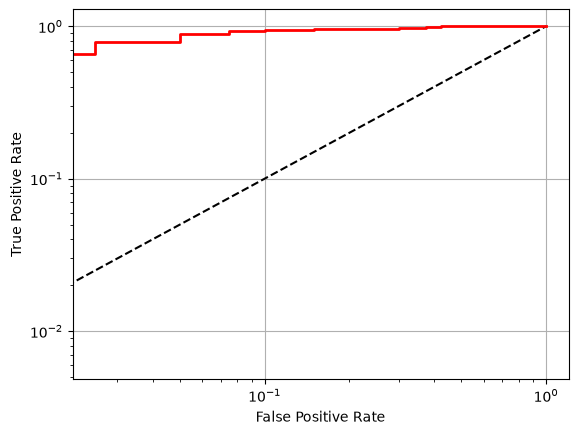

In [10]:
roc_plot_single(res_lira)

#### LiRA record-level vulnerability scores

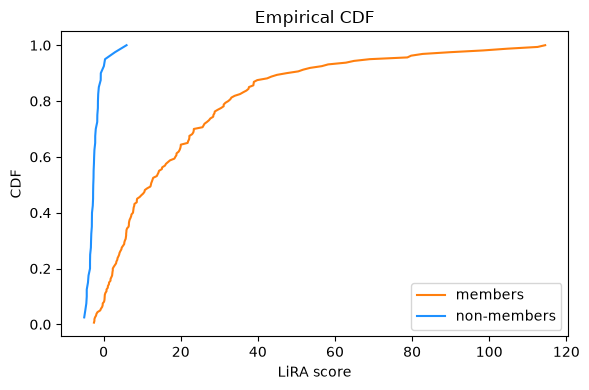

In [11]:
plot_lira_cdf(res_lira)

## Report

In [12]:
print(f"See report and files generated in folder: '{OUTPUT_DIR}'")

See report and files generated in folder: 'output_pca'


## Researcher: Create a Differentially Private PCA with OpenDP

In [13]:
# Create DP-PCA
dp_model = opendp.sklearn.decomposition.PCA(
    n_components=N_COMPONENTS,
    n_samples=X_train.shape[0],
    n_features=X_train.shape[1],
    row_norm=0.1,
    epsilon=DP_EPSILON,
)
dp_model.fit(X_train)

# Wrap model and data
target = Target(
    model=dp_model,
    model_task="preprocessor",
    dataset_name="synthetic",
    X_train=X_train,
    X_test=X_test,
)

target.save(DP_TARGET_DIR)

## Researcher/Auditor: Define and execute the audit (attacks) on the DP-PCA

### Run a likelihood ratio attack on the DP-PCA using reconstruction errors

In [14]:
for key, value in model.__dict__.items():
    if isinstance(value, np.ndarray):
        print(
            f"{key}: type={type(value).__name__}, "
            f"shape={value.shape}, dtype={value.dtype}, "
            f"size={value.nbytes:,} bytes"
        )
    else:
        print(f"{key}: {type(value).__name__} = {value}")

n_components: int = 5
copy: bool = True
whiten: bool = False
svd_solver: str = auto
tol: float = 0.0
iterated_power: str = auto
n_oversamples: int = 10
power_iteration_normalizer: str = auto
random_state: int = 1
n_features_in_: int = 100
_fit_svd_solver: str = full
mean_: type=ndarray, shape=(100,), dtype=float64, size=800 bytes
noise_variance_: float64 = 0.901493632899233
n_samples_: int = 160
n_components_: int = 5
components_: type=ndarray, shape=(5, 100), dtype=float64, size=4,000 bytes
explained_variance_: type=ndarray, shape=(5,), dtype=float64, size=40 bytes
explained_variance_ratio_: type=ndarray, shape=(5,), dtype=float64, size=40 bytes
singular_values_: type=ndarray, shape=(5,), dtype=float64, size=40 bytes


In [15]:
attack = LIRAAttack(
    n_shadow_models=100,
    mode="online-carlini",
    report_individual=True,
    output_dir=DP_OUTPUT_DIR,
)
result = attack.attack(target)

INFO:sacroml.attacks.likelihood_attack:Running online-carlini LiRA, fix_variance=False
INFO:sacroml.attacks.utils:Training shadow models
INFO:sacroml.attacks.utils:Trained 0 models
INFO:sacroml.attacks.utils:Trained 10 models
INFO:sacroml.attacks.utils:Trained 20 models
INFO:sacroml.attacks.utils:Trained 30 models
INFO:sacroml.attacks.utils:Trained 40 models
INFO:sacroml.attacks.utils:Trained 50 models
INFO:sacroml.attacks.utils:Trained 60 models
INFO:sacroml.attacks.utils:Trained 70 models
INFO:sacroml.attacks.utils:Trained 80 models
INFO:sacroml.attacks.utils:Trained 90 models
INFO:sacroml.attacks.likelihood_attack:Getting signals from 100 shadow models
INFO:sacroml.attacks.likelihood_attack:Computing scores
INFO:sacroml.attacks.likelihood_attack:Finished scenario
INFO:sacroml.attacks.attack:Generating report
INFO:sacroml.attacks.attack:Writing report: dp_output_pca/report.json dp_output_pca/report.pdf


In [16]:
dp_res_lira = result["attack_experiment_logger"]["attack_instance_logger"]["instance_0"]

print(f"AUC          = {dp_res_lira['AUC']:.2f}")
print(f"TPR@0.1% FPR = {dp_res_lira['TPR@0.1%']:.4f}")

AUC          = 0.43
TPR@0.1% FPR = 0.0000


#### DP-PCA LiRA ROC Curve

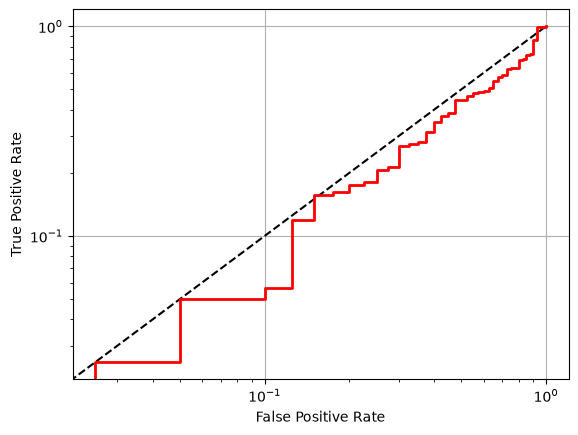

In [17]:
roc_plot_single(dp_res_lira)

## Report

In [18]:
print(f"See DP-PCA report and files generated in folder: '{DP_OUTPUT_DIR}'")

See DP-PCA report and files generated in folder: 'dp_output_pca'
